In [1]:
from sklearn.datasets import load_wine
import pandas as pd

wine = load_wine(as_frame=True)
df = wine.frame

print(df.shape)
print(df.head())

(178, 14)
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  target  
0

In [2]:
X = df.drop(columns=["target"])

print("Shape of features:", X.shape)
print(X.head())

Shape of features: (178, 13)
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  

In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)
print("First 5 rows:")
print(X_scaled[:5])

Scaled data shape: (178, 13)
First 5 rows:
[[ 1.51861254 -0.5622498   0.23205254 -1.16959318  1.91390522  0.80899739
   1.03481896 -0.65956311  1.22488398  0.25171685  0.36217728  1.84791957
   1.01300893]
 [ 0.24628963 -0.49941338 -0.82799632 -2.49084714  0.01814502  0.56864766
   0.73362894 -0.82071924 -0.54472099 -0.29332133  0.40605066  1.1134493
   0.96524152]
 [ 0.19687903  0.02123125  1.10933436 -0.2687382   0.08835836  0.80899739
   1.21553297 -0.49840699  2.13596773  0.26901965  0.31830389  0.78858745
   1.39514818]
 [ 1.69154964 -0.34681064  0.4879264  -0.80925118  0.93091845  2.49144552
   1.46652465 -0.98187536  1.03215473  1.18606801 -0.42754369  1.18407144
   2.33457383]
 [ 0.29570023  0.22769377  1.84040254  0.45194578  1.28198515  0.80899739
   0.66335127  0.22679555  0.40140444 -0.31927553  0.36217728  0.44960118
  -0.03787401]]


In [4]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_

print("Explained Variance Ratio:")
print(explained_variance)

print("\nCumulative Explained Variance:")
print(explained_variance.cumsum())

Explained Variance Ratio:
[0.36198848 0.1920749  0.11123631 0.0706903  0.06563294 0.04935823
 0.04238679 0.02680749 0.02222153 0.01930019 0.01736836 0.01298233
 0.00795215]

Cumulative Explained Variance:
[0.36198848 0.55406338 0.66529969 0.73598999 0.80162293 0.85098116
 0.89336795 0.92017544 0.94239698 0.96169717 0.97906553 0.99204785
 1.        ]


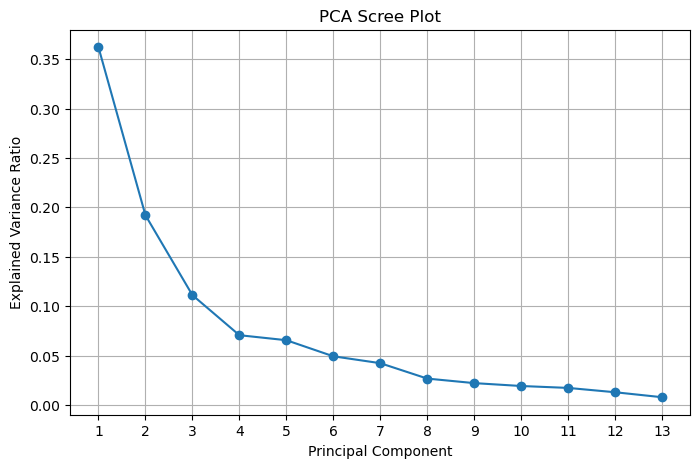

In [5]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker='o'
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Scree Plot")
plt.xticks(range(1, 14))
plt.grid(True)

plt.show()

In [6]:
pca_2 = PCA(n_components=2)

X_pca_2 = pca_2.fit_transform(X_scaled)

print("PCA transformed shape:", X_pca_2.shape)
print("Explained variance by PC1 and PC2:")
print(pca_2.explained_variance_ratio_)
print("Total explained variance:",
      pca_2.explained_variance_ratio_.sum())

PCA transformed shape: (178, 2)
Explained variance by PC1 and PC2:
[0.36198848 0.1920749 ]
Total explained variance: 0.5540633835693527


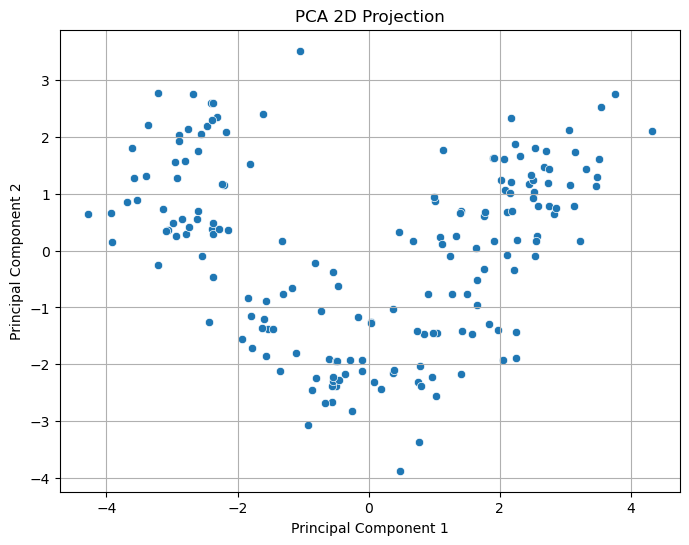

In [7]:
import seaborn as sns

pca_df = pd.DataFrame(
    X_pca_2,
    columns=["PC1", "PC2"]
)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2"
)

plt.title("PCA 2D Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)

plt.show()

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []
silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

print("Inertia:")
print(inertia)

print("\nSilhouette Scores:")
print(silhouette_scores)

C:\Users\NEHA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\NEHA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\NEHA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\NEHA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows wi

Inertia:
[1658.7588524290954, 1277.928488844642, 1175.428333103347, 1109.5127392938243, 1046.0023332143637, 981.5952326111658, 935.2012114738545, 889.8929111933174, 845.8952366525513]

Silhouette Scores:
[0.25931695553182543, 0.2848589191898987, 0.26017035223704527, 0.2016190829407409, 0.23716725754166543, 0.2036275812271175, 0.1570139556393107, 0.14988199178183517, 0.1436384079124149]


C:\Users\NEHA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\NEHA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


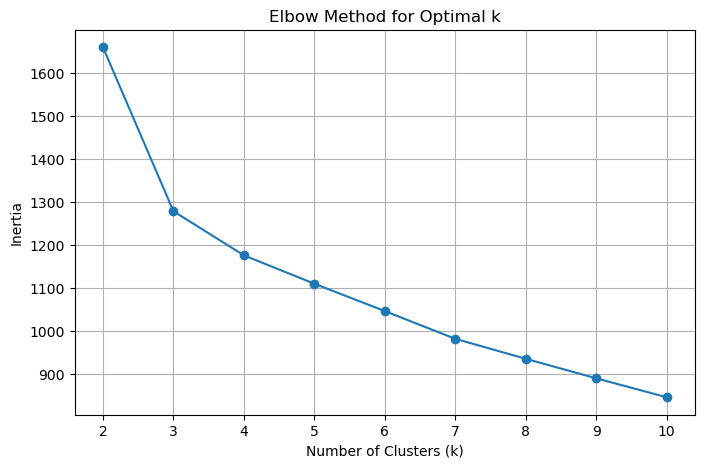

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, inertia, marker='o')

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.xticks(k_values)
plt.grid(True)

plt.show()

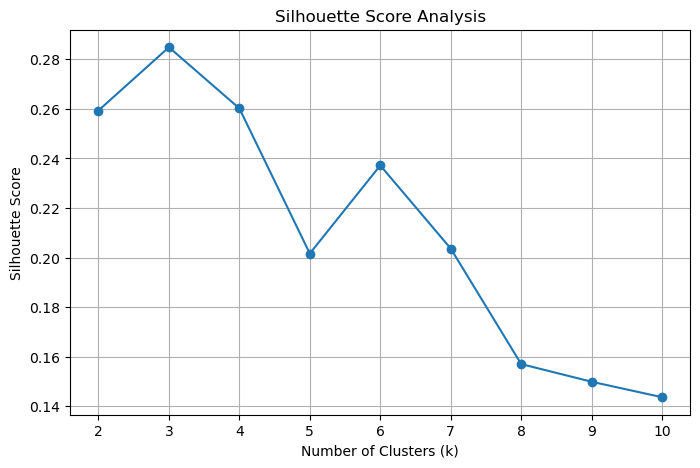

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, silhouette_scores, marker='o')

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Analysis")
plt.xticks(k_values)
plt.grid(True)

plt.show()

In [2]:
from sklearn.cluster import KMeans

In [5]:
import pandas as pd
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
df = wine.frame

X = df.drop(columns=["target"])

print("Dataset shape:", df.shape)
print("Features shape:", X.shape)

Dataset shape: (178, 14)
Features shape: (178, 13)


In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (178, 13)


In [7]:
from sklearn.cluster import KMeans

kmeans_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_final.fit_predict(X_scaled)

print("Cluster labels:")
print(kmeans_labels)

print("\nCluster counts:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

Cluster labels:
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 1 0 0 0 0 0 0 0 0 0 0 0 2
 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 0 0 2 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]

Cluster counts:
0    65
1    51
2    62
Name: count, dtype: int64


C:\Users\NEHA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
from sklearn.decomposition import PCA

pca_2 = PCA(n_components=2)

X_pca_2 = pca_2.fit_transform(X_scaled)

print("PCA transformed shape:", X_pca_2.shape)
print("Explained variance by PC1 and PC2:")
print(pca_2.explained_variance_ratio_)
print("Total explained variance:",
      pca_2.explained_variance_ratio_.sum())

PCA transformed shape: (178, 2)
Explained variance by PC1 and PC2:
[0.36198848 0.1920749 ]
Total explained variance: 0.5540633835693527


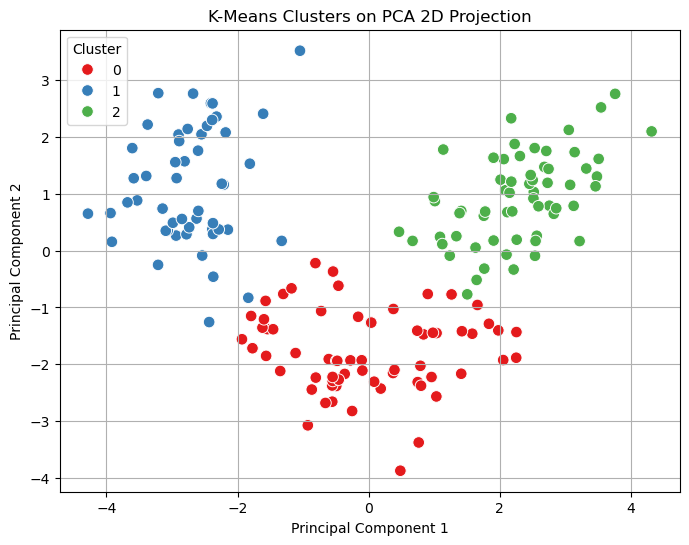

In [12]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_pca_2[:, 0],
    y=X_pca_2[:, 1],
    hue=kmeans_labels,
    palette="Set1",
    s=70
)

plt.title("K-Means Clusters on PCA 2D Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(True)

plt.show()

In [13]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=1.5,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_scaled)

print("DBSCAN Cluster Labels:")
print(dbscan_labels)

print("\nCluster Counts:")
print(pd.Series(dbscan_labels).value_counts().sort_index())

DBSCAN Cluster Labels:
[-1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1]

Cluster Counts:
-1    178
Name: count, dtype: int64


In [14]:
dbscan = DBSCAN(
    eps=2.1,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_scaled)

print("DBSCAN Cluster Labels:")
print(dbscan_labels)

print("\nCluster Counts:")
print(pd.Series(dbscan_labels).value_counts().sort_index())

DBSCAN Cluster Labels:
[ 0  0  0  0  0  0  0  0  0  0  0  0  0 -1 -1  0  0  0  0  0  0 -1  0  0
  0 -1  0  0  0  0  0  0  0  0  0  0  0  0  0 -1  0 -1  0 -1  0 -1 -1  0
  0  0 -1  0  0  0  0  0  0  0  0 -1 -1 -1 -1 -1  0 -1 -1  0 -1 -1 -1 -1
 -1 -1 -1 -1  0 -1 -1 -1  0  0  0 -1 -1  0  0  0  0  0  0  0  0  0 -1 -1
 -1  0 -1 -1  0  0  0  0  0 -1  0  0  0 -1 -1  0 -1  0  0 -1  0  0 -1 -1
  0 -1 -1 -1 -1  0  0 -1  0 -1 -1  1  1  1 -1 -1 -1 -1  2  1  1  1  1  2
  1  1 -1  2  2  2  2  2 -1  2 -1  2  2 -1 -1 -1  2  1  1  1  2  2  2  2
  2 -1  1  2  2  2  2  2 -1 -1]

Cluster Counts:
-1    62
 0    82
 1    13
 2    21
Name: count, dtype: int64


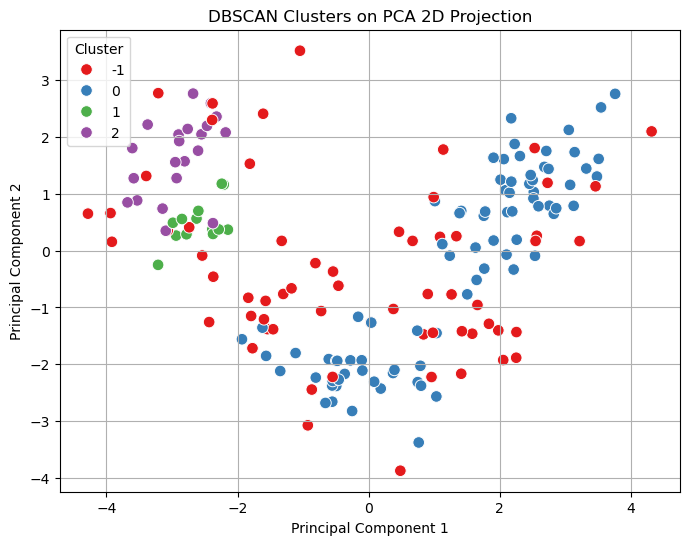

In [15]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_pca_2[:, 0],
    y=X_pca_2[:, 1],
    hue=dbscan_labels,
    palette="Set1",
    s=70
)

plt.title("DBSCAN Clusters on PCA 2D Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(True)

plt.show()

In [16]:
from sklearn.cluster import AgglomerativeClustering

hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

print("Hierarchical Cluster Labels:")
print(hierarchical_labels)

print("\nCluster Counts:")
print(pd.Series(hierarchical_labels).value_counts().sort_index())

Hierarchical Cluster Labels:
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 1 1 0 0 0 2 2 0 1 0 1 2 0 2
 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 0 0 2 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]

Cluster Counts:
0    58
1    56
2    64
Name: count, dtype: int64


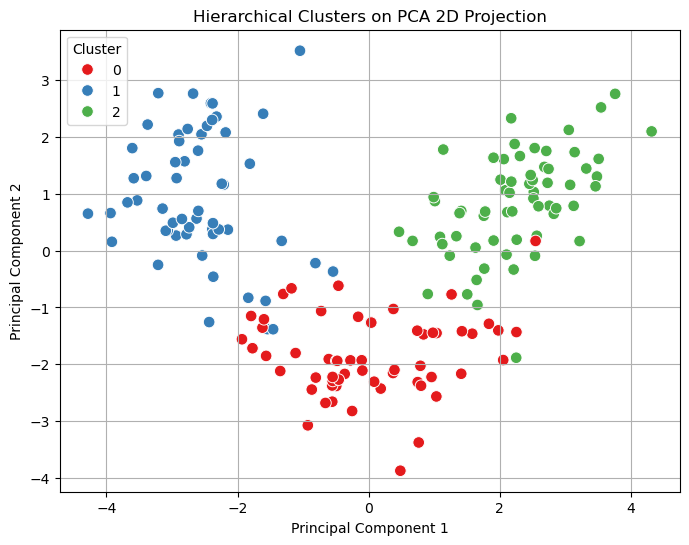

In [17]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_pca_2[:, 0],
    y=X_pca_2[:, 1],
    hue=hierarchical_labels,
    palette="Set1",
    s=70
)

plt.title("Hierarchical Clusters on PCA 2D Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(True)

plt.show()

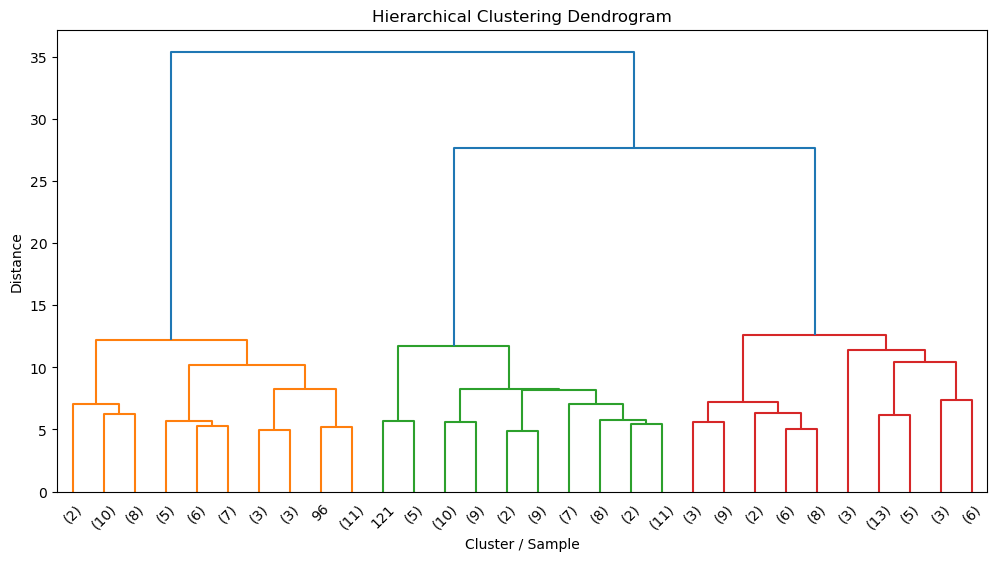

In [18]:
from scipy.cluster.hierarchy import dendrogram, linkage

linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 6))

dendrogram(
    linked,
    truncate_mode="lastp",
    p=30
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster / Sample")
plt.ylabel("Distance")

plt.show()

## Findings

### PCA Findings
- The Wine dataset contains 178 samples and 13 numerical features.
- All numerical features were standardized before applying PCA.
- The first principal component explains 36.20% of the variance.
- The second principal component explains 19.21% of the variance.
- The first two principal components together explain 55.41% of the total variance.
- The PCA 2D projection was used to visualize the clustering structure.

### K-Means Findings
- The Elbow Method and Silhouette Score were used to evaluate different values of k.
- Among the tested values from 2 to 10, k = 3 produced the highest Silhouette Score of approximately 0.285.
- Final K-Means clustering with 3 clusters produced:
  - Cluster 0: 65 samples
  - Cluster 1: 51 samples
  - Cluster 2: 62 samples.
- The PCA 2D visualization shows three distinguishable groups.

### DBSCAN Findings
- DBSCAN was applied to the standardized features using eps = 2.1 and min_samples = 5.
- The results produced three clusters and noise points.
- Cluster 0 contains 82 samples.
- Cluster 1 contains 13 samples.
- Cluster 2 contains 21 samples.
- 62 samples were identified as noise/outliers.

### Hierarchical Clustering Findings
- Agglomerative Hierarchical Clustering with Ward linkage was applied using 3 clusters.
- The resulting clusters contain:
  - Cluster 0: 58 samples
  - Cluster 1: 56 samples
  - Cluster 2: 64 samples.
- A dendrogram was used to visualize the hierarchical structure of the observations.

## Conclusion

PCA successfully reduced the dimensionality of the standardized Wine dataset while preserving a substantial amount of information in the first two principal components. K-Means, DBSCAN, and Hierarchical Clustering were applied to identify groups in the data. K-Means with 3 clusters provided the highest Silhouette Score among the tested values of k. DBSCAN additionally identified noise points, while Hierarchical Clustering provided a tree-based view of the relationships among observations. The PCA-based visualizations helped compare the clustering structures in two dimensions.